In [50]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
import os
import pickle

def preprocess_goldstein_uchida(file_path, save_output=True, output_dir='Other_Datasets/preprocessed_data'):
    """
    Preprocess/Noramlize the Goldstein-Uchida dataset.

    Args:
    file_path (str): Path to the input CSV file.
    save_output (bool): Whether to save the preprocessed data and metadata.
    output_dir (str): Directory to save the preprocessed data and metadata.

    Returns:
    pd.DataFrame: The normalized data.
    list: Indices of anomaly data points.
    dict: Mapping from original indices to preprocessed indices.
    """
    data = pd.read_csv(file_path, header=None)
    
    # remove the label column
    labels = data.iloc[:, -1]
    data = data.iloc[:, :-1]
    
    data = data.astype(float)
    anomaly_indices = labels[labels == 'o'].index.tolist()
    
    # Normalize numerical features
    scaler = StandardScaler()
    data = pd.DataFrame(scaler.fit_transform(data), columns=data.columns)
    normalized_data = range_based_normalize(data)
    
    original_to_preprocessed = dict(zip(data.index, normalized_data.index))
    
    if save_output:
        os.makedirs(output_dir, exist_ok=True)
        
        base_name = os.path.splitext(os.path.basename(file_path))[0]
        
        normalized_data.to_csv(os.path.join(output_dir, f'preprocessed_{base_name}.csv'), index=False)
        np.save(os.path.join(output_dir, f'{base_name}_anomaly_indices.npy'), anomaly_indices)
        with open(os.path.join(output_dir, f'{base_name}_original_to_preprocessed.pkl'), 'wb') as f:
            pickle.dump(original_to_preprocessed, f)
        print(f"Preprocessed data, anomaly indices, and original to preprocessed index mapping saved to {output_dir}")
    
    return normalized_data, anomaly_indices, original_to_preprocessed

def range_based_normalize(data):
    """
    Normalize the data using range-based normalization.

    Args:
    data (pd.DataFrame): The input data to normalize.

    Returns:
    pd.DataFrame: The normalized data.
    """
    num_features = data.shape[1]
    max_value = 1 / num_features
    normalized_data = pd.DataFrame()

    for column in data.columns:
        min_val = data[column].min()
        max_val = data[column].max()
        normalized_data[column] = ((data[column] - min_val) / (max_val - min_val)) * max_value

    return normalized_data

In [51]:
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import pandas as pd

def perform_pca(data):
    """
    Perform PCA on the input data.
    
    Args:
    data (pd.DataFrame): Input data
    
    Returns:
    PCA: Fitted PCA object
    np.ndarray: Transformed data
    """
    scaler = StandardScaler()
    scaled_data = scaler.fit_transform(data)
    
    pca = PCA()
    pca_data = pca.fit_transform(scaled_data)
    
    return pca, pca_data

def select_features(data, num_qubits, strategy='a'):
    """
    Select features based on the specified strategy.
    
    Args:
    data (pd.DataFrame): Input data
    num_qubits (int): Number of qubits specified in main
    strategy (str): Feature selection strategy (a, b, c, d, or e)
    
    Returns:
    pd.DataFrame: Data with selected features (including added 0-features if necessary)
    list: Indices of selected features
    """
    num_features = 2**num_qubits - 1
    original_num_features = data.shape[1]
    
    #if the number of features is greater than the original number of features, add zero features rather than selecting features
    if num_features >= original_num_features:
        selected_data = data.copy()
        num_zero_features = num_features - original_num_features
        for i in range(num_zero_features):
            selected_data[f'zero_feature_{i}'] = 0
        return selected_data, list(range(num_features))
    
    #uniform random selection of features
    if strategy == 'e':
        selected_features = np.random.choice(data.columns, num_features, replace=False)
        return data[selected_features], selected_features.tolist()
    
    pca, pca_data = perform_pca(data)
    feature_importance = np.abs(pca.components_).sum(axis=0)
    
    #Select the top num_features features
    if strategy == 'a':
        selected_indices = feature_importance.argsort()[::-1][:num_features]
    #Select the bottom num_features features
    elif strategy == 'b':
        selected_indices = feature_importance.argsort()[::-1][-num_features:]
    #Select the top half and bottom half of the features
    elif strategy == 'c':
        num_top = num_features // 2
        num_bottom = num_features - num_top
        top_indices = feature_importance.argsort()[::-1][:num_top]
        bottom_indices = feature_importance.argsort()[::-1][-num_bottom:]
        selected_indices = np.concatenate([top_indices, bottom_indices])
    
    #weighted random selection based on feature importance
    elif strategy == 'd':
        selected_indices = np.random.choice(
            len(feature_importance),
            num_features,
            replace=False,
            p=feature_importance / feature_importance.sum()
        )
    else:
        raise ValueError("Invalid strategy. Choose 'a', 'b', 'c', 'd', or 'e'.")
    
    selected_features = data.columns[selected_indices]
    return data[selected_features], selected_indices.tolist()

In [52]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from math import pi
import time

from sklearn.metrics import roc_auc_score, accuracy_score
from sklearn.preprocessing import MinMaxScaler
from qiskit import QuantumCircuit
from qiskit import QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector
from qiskit.circuit.library import efficient_su2, real_amplitudes, pauli_two_design
from qiskit_machine_learning.neural_networks import SamplerQNN, EstimatorQNN
# from qiskit.primitives import StatevectorSampler as Sampler
from qiskit_machine_learning.optimizers import COBYLA
from qiskit_machine_learning.utils import algorithm_globals
from IPython.display import clear_output

import tensorflow as tf
from keras import layers

algorithm_globals.random_seed = 42

In [53]:
import pandas as pd
from sklearn.model_selection import train_test_split

# === 1. Preprocess the data ===
file_path = "Other_Datasets/pen-global-unsupervised-ad.csv" 
normalized_data, anomaly_indices, mapping = preprocess_goldstein_uchida(file_path)

# Split normal vs anomaly
anomaly_data = normalized_data.iloc[anomaly_indices]
normal_data = normalized_data.drop(anomaly_indices)

# Train/test split (only normals in training)
X_train_normal, X_test_normal = train_test_split(
    normal_data,
    test_size=0.3,
    random_state=42
)

# Build train/test sets
X_train = X_train_normal
y_train = pd.Series([0]*len(X_train), index=X_train.index)

X_test = pd.concat([X_test_normal, anomaly_data])
y_test = pd.Series([0]*len(X_test_normal) + [1]*len(anomaly_data), index=X_test.index)

# === 2. Feature selection (8 features) ===
num_qubits = 4  # because 2^3 - 1 = 7, if you want 8 features you can just pad one zero
# OR set num_qubits = 4 → 2^4 - 1 = 15, then pick top 8 manually

# Here we force select_features to return 8 features
X_train_selected, selected_indices = select_features(X_train, num_qubits=4, strategy='c')
selected_indices = selected_indices[:8]   # keep only 8 features
X_train_selected = X_train.iloc[:, selected_indices]
X_test_selected = X_test.iloc[:, selected_indices]

print("Selected 8 feature indices:", selected_indices)

# === 3. Scale features to [0, π] ===
scaler = MinMaxScaler(feature_range=(0, np.pi))

X_train_scaled = scaler.fit_transform(X_train_selected)
X_test_scaled = scaler.transform(X_test_selected)

X_train_scaled = pd.DataFrame(X_train_scaled, index=X_train_selected.index, columns=X_train_selected.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, index=X_test_selected.index, columns=X_test_selected.columns)

print("Train scaled shape:", X_train_scaled.shape)
print("Test scaled shape:", X_test_scaled.shape)


Preprocessed data, anomaly indices, and original to preprocessed index mapping saved to Other_Datasets/preprocessed_data
Selected 8 feature indices: [4, 1, 3, 14, 8, 9, 11, 10]
Train scaled shape: (503, 8)
Test scaled shape: (306, 8)


In [54]:
from qiskit.circuit import QuantumCircuit, ParameterVector
from qiskit.circuit.library import RealAmplitudes

def dense_angle_encoding(x):
    num_qubits = len(x) // 2
    circuit = QuantumCircuit(num_qubits)
    for i in range(num_qubits):
        circuit.ry(x[2 * i], i)
        circuit.rz(x[2 * i + 1], i)
    return circuit

def ansatz(num_qubits):
    return real_amplitudes(num_qubits, reps=1)

def auto_encoder_circuit(num_latent, num_trash):
    qr = QuantumRegister(num_latent + 2 * num_trash + 1, "q")
    cr = ClassicalRegister(1, "c")
    circuit = QuantumCircuit(qr, cr)
    circuit.compose(ansatz(num_latent + num_trash), range(0, num_latent + num_trash), inplace=True)
    circuit.barrier()
    auxiliary_qubit = num_latent + 2 * num_trash
    # swap test
    circuit.h(auxiliary_qubit)
    for i in range(num_trash):
        circuit.cswap(auxiliary_qubit, num_latent + i, num_latent + num_trash + i)

    circuit.h(auxiliary_qubit)
    circuit.measure(auxiliary_qubit, cr[0])
    return circuit

In [55]:
from qiskit_aer.primitives import Sampler

# Constants
num_latent = 2
num_trash = 2
total_qubits = num_latent + 2 * num_trash + 1

ae = auto_encoder_circuit(num_latent, num_trash)
dummy_encoding = QuantumCircuit(total_qubits)
qc_full = dummy_encoding.compose(ae)

# sampler = Sampler(backend_options={"device": "GPU", "method": "statevector"})
sampler = Sampler()

qnn = SamplerQNN(
    circuit=qc_full,
    input_params=[],                     # No input parameters — encoding is done externally
    weight_params=ae.parameters,         # Only train the parameters of the AE
    output_shape=2,                      # Binary outcome (0 or 1 from SWAP test)
    interpret=lambda x: x,               # Identity function, optional
    sampler=sampler
)

/tmp/ipykernel_6094/4085610092.py:15: DeprecationWarning: V1 Primitives are deprecated as of qiskit-machine-learning 0.8.0 and will be removed no sooner than 4 months after the release date. Use V2 primitives for continued compatibility and support.
  qnn = SamplerQNN(


In [56]:
import matplotlib.pyplot as plt

objective_values = []

def cost_function(params, data_subset, qnn, encoding_fn):
    """
    - params: trainable parameters of AE circuit
    - training_data: classical data (e.g., scaled_normal_training_data)
    - qnn: SamplerQNN
    - encoder_func: one of your encoding functions
    """
    data_subset = np.array(data_subset) 
    total_cost = 0

    num_encoding_qubits = num_latent + num_trash
    total_qubits = num_latent + 2 * num_trash + 1

    for x in data_subset:

        input_slice = x[:2 * num_encoding_qubits]

        # 2. Encode input
        encoding_circuit = encoding_fn(input_slice)
        encoding_qubits = encoding_circuit.num_qubits

        # 3. Extend encoding to full-size circuit
        full_circuit = QuantumCircuit(total_qubits, 1)
        full_circuit.compose(encoding_circuit, qubits=range(encoding_qubits), inplace=True)

        # 4. Add autoencoder with current parameters
        ae = auto_encoder_circuit(num_latent, num_trash)
        ae = ae.assign_parameters({p: v for p, v in zip(ae.parameters, params)})
        full_circuit = full_circuit.compose(ae)

        # 5. Evaluate using the Sampler (NOT qnn.forward!)
        job = qnn.sampler.run([full_circuit])
        result = job.result()
        quasi_dist = result.quasi_dists[0]
        p0 = quasi_dist.get(0, 0)

        total_cost += 1 - p0  # want to maximize p(0)

    avg_cost = total_cost / len(data_subset)
    objective_values.append(avg_cost)

    # Plot current progress
    clear_output(wait=True)
    plt.figure(figsize=(8, 4))
    plt.plot(objective_values, label="Training Loss (1 - p0)")
    plt.xlabel("Iteration")
    plt.ylabel("Loss")
    plt.title("Training Loss Curve")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

    return avg_cost


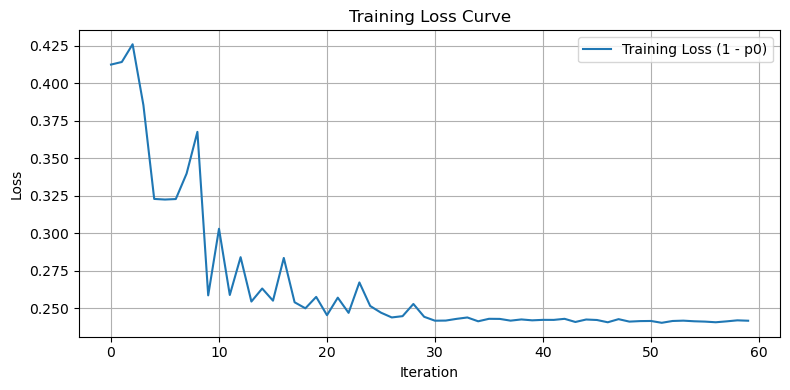

In [57]:
num_params = len(auto_encoder_circuit(num_latent, num_trash).parameters)
initial_params = np.random.rand(num_params)

# Optimize
optimizer = COBYLA(maxiter=60)
result = optimizer.minimize(
    fun=lambda p: cost_function(p, X_train_scaled, qnn, dense_angle_encoding),
    x0=initial_params
)
trained_params = result.x

In [41]:
from qiskit.qpy import dump
import os

model_name = "Models/QAE/Others/Goldstein_Pen_Global_8f_qae_dense"
os.mkdir(model_name)

with open(f"{model_name}/ae.qpy", "wb") as f:
    dump(ae, f)

np.save(f"{model_name}/weight_param_names", [p.name for p in ae.parameters])
np.save(f"{model_name}/trained_parameters", trained_params)

In [58]:
from tqdm import tqdm

def compute_anomaly_scores(qnn, input_data, trained_params, encoding_fn, batch_size=64):
    input_data = np.array(input_data) 
    scores = []
    total_qubits = num_latent + 2 * num_trash + 1
    num_encoding_qubits = num_latent + num_trash

    ae = auto_encoder_circuit(num_latent, num_trash)
    ae = ae.assign_parameters({p: v for p, v in zip(ae.parameters, trained_params)})

    start = time.time()
    for i in tqdm(range(0, len(input_data), batch_size), desc="Running inference"):
        batch = input_data[i : i + batch_size]
        circuits = []

        for x in batch:
            qc = QuantumCircuit(total_qubits, 1)

            input_slice = x[:2 * num_encoding_qubits]
            
            # 2. Encode input
            encoded = encoding_fn(input_slice)
            qc.compose(encoded, qubits=range(encoded.num_qubits), inplace=True)

            # 3. Add trained AE circuit
            qc.compose(ae, inplace=True)

            circuits.append(qc)

        # 4. Run sampler
        job = qnn.sampler.run(circuits)
        result = job.result()

        # 5. Extract p(1) as anomaly score
        for quasi in result.quasi_dists:
            p1 = quasi.get(1, 0)
            scores.append(p1)

    elapsed = time.time() - start
    print(f"\nAll batches processed in {elapsed:.4f} seconds.")

    return np.array(scores), elapsed



In [59]:
train_scores, train_time = compute_anomaly_scores(
    qnn,
    X_train_scaled,
    trained_params,
    encoding_fn=dense_angle_encoding,
    batch_size=64
)

threshold = 0.5 * (np.min(train_scores) + np.max(train_scores))

Running inference: 100%|██████████████████████████| 8/8 [00:00<00:00, 16.46it/s]


All batches processed in 0.4871 seconds.


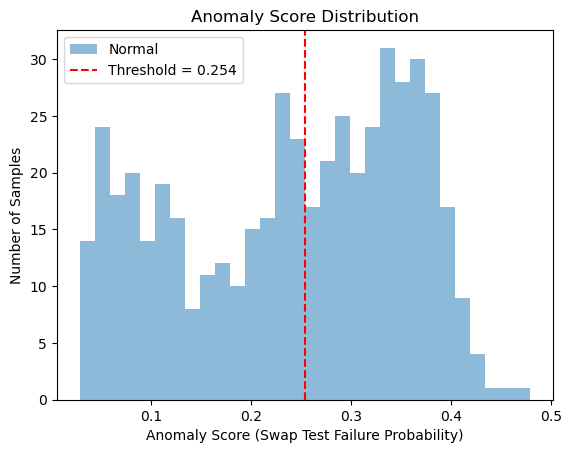

In [60]:
y_pred = (train_scores < threshold).astype(int)

# --- Histogram of scores ---
plt.hist(train_scores, bins=30, alpha=0.5, label='Normal')
plt.axvline(threshold, color='red', linestyle='--', label=f"Threshold = {threshold:.3f}")
plt.xlabel("Anomaly Score (Swap Test Failure Probability)")
plt.ylabel("Number of Samples")
plt.title("Anomaly Score Distribution")
plt.legend()
plt.show()

In [61]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score
)
import numpy as np
import tensorflow as tf
from keras import layers

def evaluate_model(y_true, y_pred, scores, time, threshold=0.2, model_name="Model"):
    """
    Evaluates a model and returns metrics formatted for copy-pasting.

    Parameters:
        y_true (np.array): Ground truth labels (0=normal, 1=anomaly).
        scores (np.array): Anomaly scores (lower = more anomalous).
        threshold (float): Threshold for anomaly decision.
        model_name (str): Name of the model.

    Returns:
        dict: Dictionary of metrics (can print or format for LaTeX).
    """

    precision = precision_score(y_true, y_pred, zero_division=0)
    accuracy = accuracy_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    auroc = roc_auc_score(y_true, scores)

    cm = confusion_matrix(y_true, y_pred)
    clf_report = classification_report(y_true, y_pred, digits=2)

    result = {
        "Model": model_name,
        "Precision": f"{precision:.3f}",
        "Accuracy": f"{accuracy:.3f}",
        "Recall": f"{recall:.3f}",
        "F1-Score": f"{f1:.3f}",
        "Matrix": f"TP={cm[1,1]}, FP={cm[0,1]}, FN={cm[1,0]}, TN={cm[0,0]}",
        "AUROC": f"{auroc:.3f}",
        "Data Loading + Inference Time (s)": f"{time:.4f}s",
        "Clf Report": clf_report.strip()
    }

    return result

In [62]:
scores, elapsed_time = compute_anomaly_scores(
    qnn,
    X_test_scaled,
    trained_params,
    encoding_fn=dense_angle_encoding,
    batch_size=64
)

Running inference: 100%|██████████████████████████| 5/5 [00:15<00:00,  3.12s/it]


All batches processed in 15.6192 seconds.


Model: Models/QAE/Others/Goldstein_Pen_Global_8f_qae_dense
Precision: 0.354
Accuracy: 0.526
Recall: 0.744
F1-Score: 0.480
Matrix: TP=67, FP=122, FN=23, TN=94
AUROC: 0.715
Data Loading + Inference Time (s): 15.6192s
Clf Report: precision    recall  f1-score   support

           0       0.80      0.44      0.56       216
           1       0.35      0.74      0.48        90

    accuracy                           0.53       306
   macro avg       0.58      0.59      0.52       306
weighted avg       0.67      0.53      0.54       306


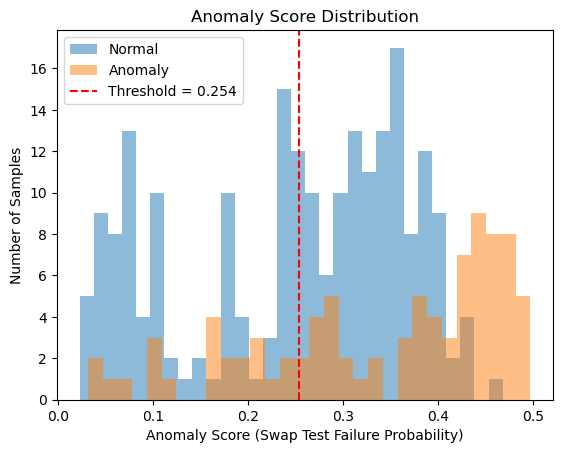

In [63]:
# threshold = 0.15

X_test = pd.concat([X_test_normal, anomaly_data])
y_test = pd.Series([0]*len(X_test_normal) + [1]*len(anomaly_data), index=X_test.index)

y_pred = y_pred = (scores > threshold).astype(int)
y_true = np.array(y_test).astype(int)[:len(scores)]

metrics = evaluate_model(
    y_true=y_true,
    y_pred=y_pred,
    scores=scores,
    time=elapsed_time,
    threshold=threshold,  # same threshold used in predict
    model_name=model_name
)

# Print clean table row for your notes
for k, v in metrics.items():
    print(f"{k}: {v}")

# --- Histogram of scores ---
plt.hist(scores[y_true == 0], bins=30, alpha=0.5, label='Normal')
plt.hist(scores[y_true == 1], bins=30, alpha=0.5, label='Anomaly')
plt.axvline(threshold, color='red', linestyle='--', label=f"Threshold = {threshold:.3f}")
plt.xlabel("Anomaly Score (Swap Test Failure Probability)")
plt.ylabel("Number of Samples")
plt.title("Anomaly Score Distribution")
plt.legend()
plt.show()